# Industrial Surface Defect Segmentation
**DL & GenAI Project (BSDA2001P), T3-2026** - Roll No: **23f1002246**

**Task:** for each 128 x 800 grayscale steel-surface image, predict a pixel mask for each of 4 defect
classes (`defect_a`...`defect_d`), submitted as run-length encoding. 11,393 training images, 3,000 test
images -> 12,000 submission rows.

**Pipeline**
```
train.csv (RLE) -> decode masks -> stratified split -> augment -> model (1 -> 4 channels)
     -> BCE+Dice loss -> best checkpoint by val score -> ensemble + flip TTA
     -> per-class threshold + min-area filter -> RLE encode -> submission.csv
```
**Contents:** 0 Setup · 1 Baseline · 2 Project code · 3 Sanity checks · 4 Data at a glance ·
5 Train 3 models · 6 Experiments · 7 Post-processing · 8 Error analysis · 9 Submission · 10 Results

## 0. Setup
**Notebook settings:** Accelerator = **GPU P100** or **T4** (the code uses one GPU), Internet = **On**
(pretrained ImageNet weights are downloaded). Add-ons -> Secrets: `WANDB_API_KEY` attached.

For a long run use **Save Version -> Save & Run All**: it runs in the background and keeps
`/kaggle/working` as the version's output.

In [1]:
import os, glob, torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/train.csv', recursive=True)[0])
print("data:", DATA_DIR, "|", os.listdir(DATA_DIR))
print("train images:", len(os.listdir(f"{DATA_DIR}/train")), "| test images:", len(os.listdir(f"{DATA_DIR}/test")))

torch 2.11.0+cu130 | CUDA: True | Tesla T4
data: /kaggle/input/competitions/industrial-surface-defect-detection/public | ['sample_submission.csv', 'train.csv', 'test', 'train']
train images: 11393 | test images: 3000


In [2]:
# segmentation_models_pytorch provides the pretrained encoders.
!pip install -q segmentation-models-pytorch==0.6.0
# Keep ONLY the smp wheel (--no-deps) for an offline inference notebook later.
# Without --no-deps pip also downloads numpy/pillow/etc., and installing those offline can
# replace Kaggle's own versions and break the environment.
!pip download -q segmentation-models-pytorch==0.6.0 --no-deps -d /kaggle/working/wheels
!ls /kaggle/working/wheels

segmentation_models_pytorch-0.6.0-py3-none-any.whl


In [3]:
import wandb
from kaggle_secrets import UserSecretsClient
wandb.login(key=UserSecretsClient().get_secret('WANDB_API_KEY'))

WANDB_ENTITY = '23f1002246-dl-gen-ai'      # your W&B team (Entity ID)
WANDB_PROJECT = '23f1002246-t32026'

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


**`run()` helper:** a failing `!python ...` line does *not* stop a notebook - with Save & Run All the
remaining cells would keep going for hours on missing files. `run()` streams the output and raises an
error as soon as a step fails.

In [4]:
import subprocess
def run(cmd):
    """Run a shell command, show its output live, and stop the notebook if it fails."""
    print("$", cmd)
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    lines = []
    for line in p.stdout:
        print(line, end="")
        lines.append(line)
    if p.wait() != 0:
        raise RuntimeError(f"Command failed (exit code {p.returncode}): {cmd}")
    return "".join(lines)   # lets later cells read numbers out of the output

## 1. Baseline submission (Milestone 0)
The first submission was a straight copy of `sample_submission.csv` and scored **0.273** on the public LB.
That file is *not* empty: 1,146 of its 12,000 rows contain random masks. They act as false positives on
pairs whose truth is empty, so the 30% "empty" part of the score drops from 0.30 to about
0.30 x (1 - 1146/12000) = 0.27 - matching the leaderboard and confirming how the metric works.

A truly empty submission (below) should score about **0.30**: Dice part = 0, every empty pair correct.
That is the floor; the course cutoff of **0.65** needs roughly 0.5 foreground Dice from a trained model.
Saved as `baseline_submission.csv` so it never overwrites the real `submission.csv`.

In [5]:
import pandas as pd
base = pd.read_csv(f"{DATA_DIR}/sample_submission.csv", keep_default_na=False)
print("non-empty rows in sample_submission:", (base.mask_rle.str.strip() != "").sum())
base["mask_rle"] = " "          # predict 'no defect' for every image x class
base.to_csv("/kaggle/working/baseline_submission.csv", index=False)

non-empty rows in sample_submission: 1146


## 2. Project code (`src/`)
The same files as the GitHub repo. Preprocessing, model, training, post-processing and inference live in
separate modules and are run as `python -m src.<script>` - this keeps the notebook short and the code
reusable (an L1 checklist item).

Note: `%%writefile` must be the **first line** of its cell, one file per cell.

In [6]:
import os
os.makedirs('src', exist_ok=True)
open('src/__init__.py', 'w').close()  # makes src a package

### `config.py` - constants in one place
Image size (128 x 800), the 4 class names in output-channel order, the metric weights, the seed, and
`find_data_dir()`, which locates `train.csv` both on Kaggle (`/kaggle/input/...`) and locally.

**Viva:** *Why a config file?* Every script imports the same constants, so changing (say) the class
order can't silently break one script and not another.

In [7]:
%%writefile src/config.py
"""Project-wide constants and path helpers.

Everything that more than one script needs lives here, so there is exactly one
place to change an image size, a class list or a data path.
"""
import os

# Image geometry (all images in this competition are 128 x 800)
IMG_HEIGHT = 128
IMG_WIDTH = 800

# The four anomaly categories, in the order used for the 4 output channels
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
NUM_CLASSES = len(CLASSES)

# Weights of the official competition score
W_DICE, W_FP, W_EMPTY = 0.70, 0.20, 0.10

SEED = 42


def find_data_dir(explicit=None):
    """Return the folder that contains train.csv, train/ and test/.

    Works locally (./data/public) and on Kaggle (/kaggle/input/<competition>).
    """
    if explicit:  # an explicit path must be right; don't silently fall back
        if not os.path.isfile(os.path.join(explicit, "train.csv")):
            raise FileNotFoundError(f"No train.csv in --data_dir {explicit}")
        return explicit
    candidates = ["data/public", "../data/public", "data"]
    if os.path.isdir("/kaggle/input"):
        for root, dirs, files in os.walk("/kaggle/input", followlinks=True):
            if "train.csv" in files and "sample_submission.csv" in files:
                candidates.insert(0, root)
                break
    for c in candidates:
        if c and os.path.isfile(os.path.join(c, "train.csv")):
            return c
    raise FileNotFoundError(
        "Could not find train.csv. Pass --data_dir pointing at the competition folder."
    )


Writing src/config.py


### `rle.py` - run-length encoding
A mask is flattened **column-major** (`order="F"`: down each column, then the next column) and written as
`start length` pairs, with **1-indexed** starts. Empty mask -> `" "`.

Worked example with height 128: `3201 12` -> 0-indexed pixel 3200 -> column `3200 // 128 = 25`,
row `3200 % 128 = 0` -> 12 pixels going **down** column 25 from the top.

`rle_encode` pads the flat mask with a 0 at both ends, finds every position where the value changes
(run starts and run ends), then turns each end position into a length.

**Viva (likely live-coding task):** write `rle_decode` from memory. What breaks if you use `order="C"`?
(masks come out transposed/scrambled - every prediction would score ~0.)

In [8]:
%%writefile src/rle.py
"""Run-length encoding helpers.

Competition format: "start length start length ...", where
  * start is 1-indexed,
  * pixels are numbered in COLUMN-MAJOR order (top to bottom, then left to right),
  * an empty mask is written as a single space " ".
"""
import numpy as np

from .config import IMG_HEIGHT, IMG_WIDTH


def rle_decode(rle, height=IMG_HEIGHT, width=IMG_WIDTH):
    """Turn an RLE string into a (height, width) uint8 mask of 0/1."""
    flat = np.zeros(height * width, dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        numbers = np.asarray(rle.split(), dtype=np.int64)
        starts, lengths = numbers[0::2] - 1, numbers[1::2]  # make starts 0-indexed
        for s, l in zip(starts, lengths):
            flat[s:s + l] = 1
    # order="F" = column-major, matching the competition's numbering
    return flat.reshape((height, width), order="F")


def rle_encode(mask):
    """Turn a (height, width) binary mask into an RLE string (" " if empty)."""
    flat = np.asarray(mask, dtype=np.uint8).flatten(order="F")
    # pad with zeros so every run has a clear start and end
    padded = np.concatenate([[0], flat, [0]])
    changes = np.where(padded[1:] != padded[:-1])[0] + 1  # 1-indexed positions
    if len(changes) == 0:
        return " "
    changes[1::2] -= changes[0::2]  # convert end positions into run lengths
    return " ".join(str(x) for x in changes)


Writing src/rle.py


### `metric.py` - local version of the competition score
$Dice = \frac{2|X \cap Y|}{|X| + |Y|}$ - for binary masks this is exactly the **pixel-level F1 score**
(precision and recall of foreground pixels), which is why we report it where the guidelines say "F1".

Every (image, class) pair is either
* **positive** (ground truth has pixels) -> contributes its Dice to *foreground Dice* (70%), or
* **empty** -> contributes 1 if we predicted nothing, else 0, to the *empty / false-positive* part (30%).

The competition page doesn't give exact formulas for the 20% and 10% parts, so locally both are scored
strictly (any false pixel = 0). The local score is therefore a slightly pessimistic estimate.

**Viva:** *Why not plain average Dice?* ("naive Dice") ~85% of pairs are empty, and empty-vs-empty
counts as Dice 1, so predicting nothing scores ~0.84 naive Dice but only 0.30 on the real metric.

In [9]:
%%writefile src/metric.py
"""Local re-implementation of the competition score.

The score is computed over every (image, defect_type) pair:

* Foreground Dice (70%): mean Dice over pairs whose ground truth is NOT empty.
* False Positive Score (20%) and Empty Accuracy (10%): computed over pairs whose
  ground truth IS empty. The competition page does not give exact formulas for
  these two, so locally we use the strictest reading for both: a pair scores 1
  only when the prediction is completely empty, otherwise 0. That makes the
  local score a slightly pessimistic estimate of the leaderboard score.

So locally:  score = 0.70 * fg_dice + 0.30 * empty_accuracy
"""
import numpy as np

from .config import W_DICE, W_EMPTY, W_FP


def dice(pred, gt, eps=1e-7):
    """Dice = 2|X ∩ Y| / (|X| + |Y|) for two binary masks."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    return (2.0 * inter + eps) / (pred.sum() + gt.sum() + eps)


class ScoreAccumulator:
    """Collects per-pair results batch by batch, then reports the final score.

    Results are kept per class, so we can also print a per-class breakdown.
    """

    def __init__(self, num_classes):
        self.fg_dice = [[] for _ in range(num_classes)]     # Dice on positive pairs
        self.empty_ok = [[] for _ in range(num_classes)]    # 1/0 on empty pairs
        self.naive = [[] for _ in range(num_classes)]       # Kaggle-style naive Dice

    def update(self, preds, gts):
        """preds, gts: arrays of shape (batch, classes, H, W) holding 0/1."""
        for b in range(preds.shape[0]):
            for c in range(preds.shape[1]):
                p, g = preds[b, c], gts[b, c]
                p_empty, g_empty = p.sum() == 0, g.sum() == 0
                if g_empty:
                    self.empty_ok[c].append(float(p_empty))
                    # naive Dice: empty-vs-empty counts as a perfect 1
                    self.naive[c].append(1.0 if p_empty else 0.0)
                else:
                    d = dice(p, g)
                    self.fg_dice[c].append(d)
                    self.naive[c].append(d)

    def compute(self):
        all_fg = [x for c in self.fg_dice for x in c]
        all_empty = [x for c in self.empty_ok for x in c]
        fg = float(np.mean(all_fg)) if all_fg else 0.0
        emp = float(np.mean(all_empty)) if all_empty else 1.0
        out = {
            "fg_dice": fg,
            "empty_acc": emp,
            "score": W_DICE * fg + (W_FP + W_EMPTY) * emp,
            "naive_dice": float(np.mean([x for c in self.naive for x in c])),
        }
        for c in range(len(self.fg_dice)):
            out[f"fg_dice_c{c}"] = float(np.mean(self.fg_dice[c])) if self.fg_dice[c] else 0.0
            out[f"empty_acc_c{c}"] = float(np.mean(self.empty_ok[c])) if self.empty_ok[c] else 1.0
        return out


Writing src/metric.py


### `dataset.py` - labels, split, Dataset, augmentation
* `load_labels` pivots `train.csv` (4 rows per image) into 1 row per image with one RLE column per
  class, presence flags `has_a..has_d`, and a `combo` string like `"0110"`.
* `make_split` - **stratified** 80/20 split on `combo`, so the rare `defect_b` (2.7% of images) and
  rare class combinations appear in the same proportion in train and validation.
* `DefectDataset` reads the JPEG as **grayscale** (all 3 channels are identical), decodes the 4 masks into
  a `(4, H, W)` tensor, applies augmentation to image **and** mask together, and normalises with the
  dataset mean/std (0.347 / 0.185).
* Augmentation: horizontal/vertical flips (a defect is still a defect when mirrored) and brightness /
  contrast (lighting varies between images). No 90° rotation - it would turn 128x800 into 800x128.
* `sample_weights` - for `--balanced`: images containing the rare `defect_a` or `defect_b` are drawn 3x as
  often and clean images are halved (the first models never predicted a or b).

**Viva:** *Why must geometric augmentation be applied to the mask too?* Otherwise the label no longer
lines up with the pixels. *Why not resize to 256x256?* 6.25:1 aspect ratio - thin defects would be
squashed.

In [10]:
%%writefile src/dataset.py
"""Data loading: label table, train/validation split, PyTorch Dataset."""
import os

import albumentations as A
import cv2
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Dataset

from .config import CLASSES, SEED
from .rle import rle_decode


def load_labels(data_dir):
    """Read train.csv (one row per image x class) and pivot it to one row per image.

    Returns a DataFrame with columns: image_id, defect_a..defect_d (RLE strings),
    has_a..has_d (0/1 flags) and `combo`, a string such as "0110" describing
    which classes are present (used for stratified splitting).
    """
    df = pd.read_csv(os.path.join(data_dir, "train.csv"), keep_default_na=False)
    df["mask_rle"] = df["mask_rle"].fillna("").astype(str)
    wide = df.pivot(index="image_id", columns="defect_type", values="mask_rle")
    wide = wide.reindex(columns=CLASSES).fillna("").reset_index()
    for c in CLASSES:
        wide["has_" + c[-1]] = (wide[c].str.strip() != "").astype(int)
    wide["combo"] = wide[["has_" + c[-1] for c in CLASSES]].astype(str).agg("".join, axis=1)
    return wide


def make_split(labels, val_fraction=0.2, seed=SEED):
    """Stratified split on the class combination, so the rare defect_b and rare
    combinations appear in both train and validation in the same proportion."""
    n_splits = int(round(1 / val_fraction))
    strat = labels["combo"].copy()
    # combinations seen fewer than n_splits times cannot be stratified -> group them
    counts = strat.value_counts()
    strat[strat.map(counts) < n_splits] = "rare"
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_idx, val_idx = next(skf.split(labels, strat))
    return labels.iloc[train_idx].reset_index(drop=True), labels.iloc[val_idx].reset_index(drop=True)


def get_transforms(train):
    """Augmentations from Milestone 2: flips + brightness/contrast.
    Geometric transforms are applied to the image and mask together."""
    if not train:
        return None
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    ])


def read_gray(path):
    """Images are stored as 3-channel JPEGs but are really grayscale."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    return img


class DefectDataset(Dataset):
    """Returns (image, mask) pairs.

    image: float tensor (1, H, W), scaled to [0, 1] then normalised.
    mask:  float tensor (4, H, W), one binary channel per defect class.
    When `labels` has no RLE columns (test set), the mask is all zeros.
    """

    MEAN, STD = 0.347, 0.185  # rough grayscale statistics of the training images

    def __init__(self, df, image_dir, transforms=None, has_masks=True):
        self.df = df.reset_index(drop=True)
        self.image_dir = image_dir
        self.transforms = transforms
        self.has_masks = has_masks

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = read_gray(os.path.join(self.image_dir, row["image_id"] + ".jpg"))
        h, w = img.shape
        if self.has_masks:
            mask = np.stack([rle_decode(row[c], h, w) for c in CLASSES], axis=-1)
        else:
            mask = np.zeros((h, w, len(CLASSES)), dtype=np.uint8)

        if self.transforms is not None:
            out = self.transforms(image=img, mask=mask)
            img, mask = out["image"], out["mask"]

        img = (img.astype(np.float32) / 255.0 - self.MEAN) / self.STD
        img = torch.from_numpy(img).unsqueeze(0)                         # (1, H, W)
        mask = torch.from_numpy(np.ascontiguousarray(mask.transpose(2, 0, 1))).float()  # (4, H, W)
        return img, mask, row["image_id"]


def sample_weights(train_df, empty_weight=1.0, rare_boost=3.0):
    """Per-image weights for a WeightedRandomSampler (Milestone 4, class imbalance).

    The two rarest classes, defect_a (~9.5% of images) and defect_b (~2.7%), are the ones the first
    models never predicted, so images containing them are drawn `rare_boost` times as often (an image
    with both gets it twice). Clean images are multiplied by `empty_weight` (< 1 shows fewer of them).
    """
    w = np.ones(len(train_df), dtype=np.float64)
    any_defect = train_df[["has_a", "has_b", "has_c", "has_d"]].sum(axis=1) > 0
    w[~any_defect.values] = empty_weight
    for col in ("has_a", "has_b"):
        w[train_df[col].values == 1] *= rare_boost
    return torch.as_tensor(w)


Writing src/dataset.py


### `models.py` - the three required models
| name | type | parameters | idea |
|---|---|---|---|
| `unet_scratch` | **from scratch** | 7.8 M | classic U-Net, random init |
| `unet_resnet34` | **pretrained** (ImageNet) | 24.4 M | U-Net decoder on a ResNet-34 encoder |
| `fpn_effb3` | **model of choice**, pretrained | 12.5 M | Feature Pyramid Network on EfficientNet-B3 |

**U-Net:** encoder = 4 x (max-pool halves H,W -> DoubleConv doubles channels 32->512);
decoder = 4 x (transposed conv doubles H,W -> **concatenate the skip connection** from the encoder at the
same resolution -> DoubleConv). Skips give the decoder back the fine spatial detail lost by pooling,
which is what makes the boundaries sharp. A final 1x1 conv gives 4 logits per pixel.

**Grayscale input to a pretrained encoder:** with `in_channels=1`, smp sums the pretrained RGB filters of
the first conv into one channel - same response as feeding a gray image copied into R, G and B.

**FPN vs U-Net:** FPN makes predictions from several encoder scales and merges them - lighter decoder,
good for objects of very different sizes (our defect areas range from ~30 to ~90,000 pixels).

**Output head:** 4 independent **sigmoids** (multi-label), not a softmax - 1,198 images contain more
than one defect class, and softmax would force classes to compete for each pixel.

In [11]:
%%writefile src/models.py
"""The three models required by the course:

1. `unet_scratch`   - a U-Net written from scratch, randomly initialised.
2. `unet_resnet34`  - U-Net with an ImageNet-pretrained ResNet-34 encoder.
3. `fpn_effb3`      - FPN decoder with an ImageNet-pretrained EfficientNet-B3 encoder.

All take a 1-channel grayscale image and output 4 logits per pixel
(multi-label: one independent sigmoid per defect class, because classes can
co-occur in the same image).
"""
import torch
import torch.nn as nn

from .config import NUM_CLASSES


# --------------------------------------------------------------------------
# 1. U-Net from scratch
# --------------------------------------------------------------------------
class DoubleConv(nn.Module):
    """(3x3 conv -> BatchNorm -> ReLU) twice. The basic U-Net building block."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNetScratch(nn.Module):
    """Classic encoder-decoder U-Net with skip connections.

    Encoder: 4 down-sampling stages (max-pool, then DoubleConv), channels double.
    Decoder: 4 up-sampling stages (transposed conv, concat skip, DoubleConv).
    Input H and W must be divisible by 16 (128 x 800 is fine).
    """

    def __init__(self, in_channels=1, num_classes=NUM_CLASSES, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]
        self.inc = DoubleConv(in_channels, ch[0])
        self.downs = nn.ModuleList(
            [nn.Sequential(nn.MaxPool2d(2), DoubleConv(ch[i], ch[i + 1])) for i in range(4)]
        )
        self.ups = nn.ModuleList(
            [nn.ConvTranspose2d(ch[i + 1], ch[i], kernel_size=2, stride=2) for i in reversed(range(4))]
        )
        self.up_convs = nn.ModuleList(
            [DoubleConv(ch[i] * 2, ch[i]) for i in reversed(range(4))]
        )
        self.head = nn.Conv2d(ch[0], num_classes, kernel_size=1)

    def forward(self, x):
        skips = [self.inc(x)]
        for down in self.downs:
            skips.append(down(skips[-1]))
        x = skips.pop()  # bottleneck
        for up, conv in zip(self.ups, self.up_convs):
            x = up(x)
            x = torch.cat([x, skips.pop()], dim=1)  # skip connection
            x = conv(x)
        return self.head(x)  # raw logits; apply sigmoid outside


# --------------------------------------------------------------------------
# 2 & 3. Pretrained encoders via segmentation_models_pytorch
# --------------------------------------------------------------------------
def build_model(name, pretrained=True):
    """Create a model by name. `pretrained=False` is used at inference time,
    when weights come from our own checkpoint and no download is needed."""
    if name == "unet_scratch":
        return UNetScratch()

    import segmentation_models_pytorch as smp

    weights = "imagenet" if pretrained else None
    # in_channels=1: smp adapts the first conv of the pretrained encoder to
    # grayscale by summing the RGB filter weights (Milestone 3).
    if name == "unet_resnet34":
        return smp.Unet("resnet34", encoder_weights=weights, in_channels=1, classes=NUM_CLASSES)
    if name == "fpn_effb3":
        return smp.FPN("efficientnet-b3", encoder_weights=weights, in_channels=1, classes=NUM_CLASSES)
    raise ValueError(f"Unknown model name: {name}")


MODEL_NAMES = ["unet_scratch", "unet_resnet34", "fpn_effb3"]


Writing src/models.py


### `losses.py` - BCE, soft Dice, BCE + Dice
* **BCE** - per-pixel log loss; smooth, stable gradients, but dominated by the ~99% background pixels.
* **Soft Dice** - Dice computed on probabilities instead of 0/1 masks so it is differentiable; measures
  overlap directly, so it doesn't care how many background pixels there are.
  * `mode="batch"` (**current**): one Dice per *class* over the whole batch, averaged over the classes that
    occur in the batch. A model that predicts nothing is punished.
  * `mode="image"` (**first run**, kept as `--loss bce_dice_img`): one Dice per (image, class) pair, averaged
    over all pairs. ~84% of pairs are empty and score ~1 for an empty prediction, so the networks
    collapsed to "predict nothing" - see the diagnosis after section 5.
* **BCE + Dice (default, 50/50)** - BCE stabilises early training, Dice pushes overlap.

**Viva:** *Why `BCEWithLogitsLoss` instead of sigmoid + `BCELoss`?* It fuses them with the log-sum-exp
trick, which is numerically stable (and is required for AMP). *Why did the per-image Dice fail?*
Because the loss was dominated by easy empty pairs - the classic class-imbalance trap.

In [12]:
%%writefile src/losses.py
"""Loss functions (Milestone 3): BCE, soft Dice, and their combination."""
import torch
import torch.nn as nn


class SoftDiceLoss(nn.Module):
    """1 - soft Dice. Soft = computed on probabilities, so it is differentiable.

    mode="batch" (default): Dice is computed per CLASS over the whole batch (sum over images and pixels),
        and only classes that actually occur in the batch are averaged. Classes absent from the batch
        are skipped here (BCE already punishes false alarms on them).
    mode="image": the first version of this project - Dice per (image, class) pair, averaged over ALL
        pairs. About 84% of pairs are empty and score ~1 by predicting nothing, so "predict nothing
        everywhere" becomes a cheap local minimum and the networks collapsed to it (see notebook).
    """

    def __init__(self, smooth=1.0, mode="batch"):
        super().__init__()
        self.smooth, self.mode = smooth, mode

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        if self.mode == "image":
            dims = (2, 3)                       # one Dice per (image, class)
            inter = (probs * targets).sum(dims)
            union = probs.sum(dims) + targets.sum(dims)
            return 1 - ((2 * inter + self.smooth) / (union + self.smooth)).mean()
        dims = (0, 2, 3)                        # one Dice per class, pooled over the batch
        inter = (probs * targets).sum(dims)
        union = probs.sum(dims) + targets.sum(dims)
        loss_c = 1 - (2 * inter + self.smooth) / (union + self.smooth)
        present = (targets.sum(dims) > 0).to(loss_c.dtype)   # skip classes with no positives in this batch
        return (loss_c * present).sum() / present.sum().clamp(min=1)


class BCEDiceLoss(nn.Module):
    """bce_weight * BCE + (1 - bce_weight) * Dice.

    BCE gives stable per-pixel gradients early on; Dice directly optimises
    overlap and is less affected by the huge number of background pixels.
    """

    def __init__(self, bce_weight=0.5, dice_mode="batch"):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = SoftDiceLoss(mode=dice_mode)
        self.w = bce_weight

    def forward(self, logits, targets):
        return self.w * self.bce(logits, targets) + (1 - self.w) * self.dice(logits, targets)


def build_loss(name):
    if name == "bce":
        return nn.BCEWithLogitsLoss()
    if name == "dice":
        return SoftDiceLoss()
    if name == "bce_dice":
        return BCEDiceLoss()
    if name == "bce_dice_img":              # the original per-image version, kept for the comparison
        return BCEDiceLoss(dice_mode="image")
    raise ValueError(f"Unknown loss: {name}")


Writing src/losses.py


### `utils.py` - seeding, device, early stopping
`seed_everything` fixes Python / NumPy / PyTorch seeds -> same split and initial weights every run
(reproducibility). `EarlyStopping` stops when the validation score hasn't improved for `patience`
epochs - prevents wasting GPU time and overfitting.

In [13]:
%%writefile src/utils.py
"""Small helpers shared by the scripts."""
import os
import random

import numpy as np
import torch


def seed_everything(seed=42):
    """Make runs repeatable (same split, same initial weights)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


class EarlyStopping:
    """Stop training when the validation score has not improved for `patience` epochs."""

    def __init__(self, patience=5):
        self.patience = patience
        self.best = -float("inf")
        self.bad_epochs = 0

    def step(self, score):
        """Returns (improved, should_stop)."""
        if score > self.best:
            self.best, self.bad_epochs = score, 0
            return True, False
        self.bad_epochs += 1
        return False, self.bad_epochs >= self.patience


Writing src/utils.py


### `postprocess.py` - probabilities -> final masks
Per class: pixel = 1 if probability > **threshold**; then remove **connected components** smaller than
**min_area** pixels (`cv2.connectedComponentsWithStats`, 8-connectivity).

**Viva:** *Why does this help so much here?* ~85% of image-class pairs are empty and 30% of the score
rewards predicting them empty. A few stray noisy pixels turn a perfect "empty" into a 0.

In [14]:
%%writefile src/postprocess.py
"""Turning probability maps into final masks (Milestone 5).

Two knobs per class:
  * threshold - pixel is foreground if probability > threshold
  * min_area  - connected components smaller than this many pixels are removed
                (small blobs are usually noise and cost us false positives)
"""
import cv2
import numpy as np


def remove_small_components(mask, min_area):
    """Keep only connected regions with at least `min_area` pixels."""
    if min_area <= 0 or mask.sum() == 0:
        return mask
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, dtype=bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area  # label 0 is background
    return keep[labels].astype(np.uint8)


def probs_to_masks(probs, thresholds, min_areas):
    """probs: (classes, H, W) -> binary masks (classes, H, W)."""
    out = np.zeros_like(probs, dtype=np.uint8)
    for c in range(probs.shape[0]):
        m = (probs[c] > thresholds[c]).astype(np.uint8)
        out[c] = remove_small_components(m, min_areas[c])
    return out


Writing src/postprocess.py


### `train.py` - the training loop
* **AdamW** (Adam with decoupled weight decay), lr 3e-4 for pretrained encoders, 1e-3 from scratch
  (random weights need bigger steps).
* **Cosine annealing** - lr decays smoothly from `lr` to `lr/100` over the run: big steps early,
  fine-tuning late.
* **AMP** (`torch.autocast`) - most ops run in float16 -> ~2x faster, half the memory.
  **GradScaler** multiplies the loss before `backward()` so tiny fp16 gradients don't underflow to 0,
  then un-scales before the optimiser step.
* Validation every epoch with the local competition score; the **best** epoch is checkpointed
  (not the last).
* **W&B** logs train/val loss, lr, score, fg Dice, empty accuracy and per-class metrics; the run name
  is `<model>-<loss>[-bal]`.

In [15]:
%%writefile src/train.py
"""Train one segmentation model and log everything to Weights & Biases.

Example:
    python -m src.train --model unet_resnet34 --epochs 20 --batch_size 16

The best checkpoint (by local validation score) is saved to
<out_dir>/<model>.pt together with the run config.
"""
import argparse
import json
import os
import time

import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

from .config import CLASSES, SEED, find_data_dir
from .dataset import DefectDataset, get_transforms, load_labels, make_split, sample_weights
from .losses import build_loss
from .metric import ScoreAccumulator
from .models import MODEL_NAMES, build_model
from .utils import EarlyStopping, get_device, seed_everything


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--model", choices=MODEL_NAMES, default="unet_resnet34")
    p.add_argument("--data_dir", default=None)
    p.add_argument("--out_dir", default="models")
    p.add_argument("--epochs", type=int, default=20)
    p.add_argument("--batch_size", type=int, default=16)
    p.add_argument("--lr", type=float, default=3e-4)
    p.add_argument("--weight_decay", type=float, default=1e-4)
    p.add_argument("--loss", choices=["bce", "dice", "bce_dice", "bce_dice_img"], default="bce_dice")
    p.add_argument("--balanced", action="store_true", help="oversample rare defect_b images")
    p.add_argument("--patience", type=int, default=5, help="early-stopping patience (epochs)")
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--limit", type=int, default=0, help="use only N images (quick smoke test)")
    p.add_argument("--wandb_project", default=None, help="e.g. 21f1001234-t32026")
    p.add_argument("--wandb_entity", default=None, help="W&B team name (Entity ID) that owns the project")
    p.add_argument("--wandb_mode", default="online", choices=["online", "offline", "disabled"])
    p.add_argument("--no_pretrained", action="store_true", help="random init (offline testing only)")
    p.add_argument("--seed", type=int, default=SEED)
    return p.parse_args()


def run_epoch(model, loader, loss_fn, device, optimizer=None, scaler=None, threshold=0.5):
    """One pass over `loader`. Trains if `optimizer` is given, else evaluates.
    Returns (mean loss, metric dict or None)."""
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    acc = None if training else ScoreAccumulator(len(CLASSES))
    use_amp = device.type == "cuda"

    for images, masks, _ in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        with torch.set_grad_enabled(training), torch.autocast(device.type, enabled=use_amp):
            logits = model(images)
            loss = loss_fn(logits, masks)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()   # AMP: scale loss to avoid fp16 underflow
            scaler.step(optimizer)
            scaler.update()
        else:
            preds = (torch.sigmoid(logits.float()) > threshold).cpu().numpy().astype(np.uint8)
            acc.update(preds, masks.cpu().numpy().astype(np.uint8))
        total_loss += loss.item() * images.size(0)
        n += images.size(0)
    return total_loss / max(n, 1), (acc.compute() if acc else None)


def main():
    args = parse_args()
    seed_everything(args.seed)
    device = get_device()
    data_dir = find_data_dir(args.data_dir)
    os.makedirs(args.out_dir, exist_ok=True)

    # ---------------- data ----------------
    labels = load_labels(data_dir)
    if args.limit:
        labels = labels.sample(n=min(args.limit, len(labels)), random_state=args.seed)
    train_df, val_df = make_split(labels, seed=args.seed)
    image_dir = os.path.join(data_dir, "train")
    train_ds = DefectDataset(train_df, image_dir, get_transforms(train=True))
    val_ds = DefectDataset(val_df, image_dir, get_transforms(train=False))

    sampler = None
    if args.balanced:
        sampler = WeightedRandomSampler(sample_weights(train_df, empty_weight=0.5, rare_boost=3.0), num_samples=len(train_df), replacement=True)
    train_dl = DataLoader(train_ds, batch_size=args.batch_size, shuffle=sampler is None, sampler=sampler,
                          num_workers=args.num_workers, pin_memory=True, drop_last=True)
    val_dl = DataLoader(val_ds, batch_size=args.batch_size * 2, shuffle=False,
                        num_workers=args.num_workers, pin_memory=True)
    print(f"train {len(train_ds)} | val {len(val_ds)} | device {device}")

    # ---------------- model ----------------
    model = build_model(args.model, pretrained=not args.no_pretrained).to(device)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    loss_fn = build_loss(args.loss)
    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    # cosine schedule: lr decays smoothly from args.lr to ~0 over the run
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=args.lr * 0.01)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    stopper = EarlyStopping(args.patience)

    # ---------------- wandb ----------------
    run = None
    if args.wandb_mode != "disabled":
        import wandb
        run = wandb.init(entity=args.wandb_entity, project=args.wandb_project, name=f"{args.model}-{args.loss}{'-bal' if args.balanced else ''}",
                         config={**vars(args), "params_M": round(n_params, 2)}, mode=args.wandb_mode)

    ckpt_path = os.path.join(args.out_dir, f"{args.model}.pt")
    for epoch in range(1, args.epochs + 1):
        t0 = time.time()
        train_loss, _ = run_epoch(model, train_dl, loss_fn, device, optimizer, scaler)
        val_loss, m = run_epoch(model, val_dl, loss_fn, device)
        scheduler.step()

        improved, stop = stopper.step(m["score"])
        if improved:
            torch.save({"model": args.model, "state_dict": model.state_dict(), "epoch": epoch,
                        "val": m, "args": vars(args)}, ckpt_path)

        print(f"ep {epoch:02d} | train {train_loss:.4f} | val {val_loss:.4f} | score {m['score']:.4f} "
              f"| fg_dice {m['fg_dice']:.4f} | empty_acc {m['empty_acc']:.4f} "
              f"| dice a/b/c/d {m['fg_dice_c0']:.2f}/{m['fg_dice_c1']:.2f}/{m['fg_dice_c2']:.2f}/{m['fg_dice_c3']:.2f} | {time.time() - t0:.0f}s"
              + (" *" if improved else ""))
        if run:
            log = {"epoch": epoch, "train/loss": train_loss, "val/loss": val_loss,
                   "lr": optimizer.param_groups[0]["lr"]}
            log.update({f"val/{k}": v for k, v in m.items()})
            run.log(log)
        if stop:
            print(f"Early stopping: no improvement for {args.patience} epochs.")
            break

    print(f"Best val score {stopper.best:.4f} -> {ckpt_path}")
    with open(os.path.join(args.out_dir, f"{args.model}_summary.json"), "w") as f:
        json.dump({"best_score": stopper.best, "params_M": n_params, **vars(args)}, f, indent=2)
    if run:
        run.summary["best_val_score"] = stopper.best
        run.finish()


if __name__ == "__main__":
    main()


Writing src/train.py


### `inference.py` - test predictions -> `submission.csv`
* Loads checkpoints with `pretrained=False` (weights come from our file - no internet needed).
* **Ensemble:** average sigmoid probabilities over models.
* **TTA:** also predict on horizontally and vertically flipped images, **flip the predictions back**, and
  average (4 views x models). Cheap way to reduce noise.
* Row order and IDs are copied from `sample_submission.csv`, so the file always has 12,000 rows in the
  required order; every field is quoted like the sample file.

In [16]:
%%writefile src/inference.py
"""Predict masks for the test images and write submission.csv.

Example:
    python -m src.inference --checkpoints models/unet_resnet34.pt models/fpn_effb3.pt \
        --postprocess models/postprocess.json --tta

Row order and IDs are copied from sample_submission.csv, so the file always
has exactly one row per image_id x defect_type.
"""
import argparse
import csv
import json
import os

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from .config import CLASSES, find_data_dir
from .dataset import DefectDataset
from .models import build_model
from .postprocess import probs_to_masks
from .rle import rle_encode
from .utils import get_device


def load_models(paths, device):
    """Load our own checkpoints. pretrained=False: no internet download needed."""
    models = []
    for p in paths:
        ckpt = torch.load(p, map_location=device, weights_only=False)
        m = build_model(ckpt["model"], pretrained=False)
        m.load_state_dict(ckpt["state_dict"])
        models.append(m.to(device).eval())
        print(f"loaded {p} ({ckpt['model']}, epoch {ckpt.get('epoch')})")
    return models


@torch.no_grad()
def predict_batch(models, images, tta=False):
    """Average sigmoid probabilities over models (and flips if tta=True).
    Returns a numpy array of shape (B, classes, H, W)."""
    total, count = 0, 0
    for m in models:
        flips = [[], [3], [2]] if tta else [[]]   # none, horizontal, vertical
        for dims in flips:
            x = torch.flip(images, dims) if dims else images
            with torch.autocast(images.device.type, enabled=images.device.type == "cuda"):
                p = torch.sigmoid(m(x).float())
            total = total + (torch.flip(p, dims) if dims else p)  # undo the flip
            count += 1
    return (total / count).cpu().numpy()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--checkpoints", nargs="+", required=True)
    ap.add_argument("--postprocess", default=None, help="json from src.tune_thresholds")
    ap.add_argument("--data_dir", default=None)
    ap.add_argument("--out", default="submission.csv")
    ap.add_argument("--tta", action="store_true")
    ap.add_argument("--batch_size", type=int, default=32)
    args = ap.parse_args()

    device = get_device()
    data_dir = find_data_dir(args.data_dir)
    sample = pd.read_csv(os.path.join(data_dir, "sample_submission.csv"), keep_default_na=False)

    thresholds, min_areas = [0.5] * len(CLASSES), [0] * len(CLASSES)
    if args.postprocess:
        with open(args.postprocess) as f:
            pp = json.load(f)
        thresholds, min_areas = pp["thresholds"], pp["min_areas"]
    print("thresholds", thresholds, "min_areas", min_areas)

    test_ids = pd.DataFrame({"image_id": sample["image_id"].unique()})
    ds = DefectDataset(test_ids, os.path.join(data_dir, "test"), has_masks=False)
    dl = DataLoader(ds, batch_size=args.batch_size, num_workers=2)
    models = load_models(args.checkpoints, device)

    rles = {}
    for images, _, ids in dl:
        probs = predict_batch(models, images.to(device), tta=args.tta)
        for b, image_id in enumerate(ids):
            masks = probs_to_masks(probs[b], thresholds, min_areas)
            for c, cls in enumerate(CLASSES):
                rles[(image_id, cls)] = rle_encode(masks[c])

    sub = sample.copy()
    sub["mask_rle"] = [rles[(i, d)] for i, d in zip(sub["image_id"], sub["defect_type"])]
    sub.to_csv(args.out, index=False, quoting=csv.QUOTE_ALL)  # same quoting as the sample file
    non_empty = (sub["mask_rle"].str.strip() != "").groupby(sub["defect_type"]).mean()
    print(f"wrote {args.out} ({len(sub)} rows). Fraction of non-empty predictions per class:")
    print(non_empty.round(3).to_string())


if __name__ == "__main__":
    main()


Writing src/inference.py


### `tune_thresholds.py` - choose threshold & min_area per class
Grid search on the **validation** split (never on the test set / leaderboard - that would overfit the
public LB). Thresholds {0.3...0.7} x min_area {0...1500}.

Classes can be tuned independently: each pair adds either to the Dice sum or to the empty-correct count,
so the total score is a sum of per-class contributions; maximising each class's term maximises the
total. Prints the score before (0.5, no filtering) and after tuning - put both in the report.

In [17]:
%%writefile src/tune_thresholds.py
"""Pick a probability threshold and a minimum component area for each class,
using the validation split (Milestone 5).

Example:
    python -m src.tune_thresholds --checkpoints models/unet_resnet34.pt models/fpn_effb3.pt

Several checkpoints = an ensemble (their probabilities are averaged).
Writes models/postprocess.json, which src.inference reads.

Why classes can be tuned independently: every (image, class) pair contributes
either to the Dice average (positive pairs) or to the empty-accuracy average
(empty pairs), so the total score is a sum of per-class terms.
"""
import argparse
import json
import os

import cv2
import numpy as np
import torch
from torch.utils.data import DataLoader

from .config import CLASSES, SEED, W_DICE, W_EMPTY, W_FP, find_data_dir
from .dataset import DefectDataset, load_labels, make_split
from .inference import load_models, predict_batch
from .utils import get_device

# low values on purpose: classes the model is unsure about (defect_a/b) may only reach low probabilities
THRESHOLDS = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
MIN_AREAS = [0, 50, 150, 300, 600, 1000, 1500]


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--checkpoints", nargs="+", required=True)
    p.add_argument("--data_dir", default=None)
    p.add_argument("--out", default="models/postprocess.json")
    p.add_argument("--tta", action="store_true")
    p.add_argument("--batch_size", type=int, default=32)
    p.add_argument("--limit", type=int, default=0)
    args = p.parse_args()

    device = get_device()
    data_dir = find_data_dir(args.data_dir)
    labels = load_labels(data_dir)
    if args.limit:
        labels = labels.sample(n=min(args.limit, len(labels)), random_state=SEED)
    _, val_df = make_split(labels)  # same seed -> same validation images as training
    dl = DataLoader(DefectDataset(val_df, os.path.join(data_dir, "train")), batch_size=args.batch_size)
    models = load_models(args.checkpoints, device)

    C, T, A = len(CLASSES), len(THRESHOLDS), len(MIN_AREAS)
    dice_sum = np.zeros((C, T, A))   # summed Dice over positive pairs
    empty_ok = np.zeros((C, T, A))   # count of correctly empty predictions on empty pairs
    n_pos = np.zeros(C)
    n_empty = np.zeros(C)

    for images, masks, _ in dl:
        probs = predict_batch(models, images.to(device), tta=args.tta)  # (B, C, H, W) numpy
        gts = masks.numpy().astype(bool)
        for b in range(probs.shape[0]):
            for c in range(C):
                gt = gts[b, c]
                gt_area = gt.sum()
                if gt_area > 0:
                    n_pos[c] += 1
                else:
                    n_empty[c] += 1
                for ti, thr in enumerate(THRESHOLDS):
                    m = (probs[b, c] > thr).astype(np.uint8)
                    if m.sum() == 0:
                        n_lab, lab, areas = 1, None, np.array([0])
                    else:
                        n_lab, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
                        areas = stats[:, cv2.CC_STAT_AREA]
                    for ai, min_area in enumerate(MIN_AREAS):
                        if n_lab <= 1:
                            pred = None
                        else:
                            keep = np.zeros(n_lab, dtype=bool)
                            keep[1:] = areas[1:] >= min_area
                            pred = keep[lab] if keep.any() else None
                        if gt_area > 0:
                            if pred is not None:
                                inter = np.logical_and(pred, gt).sum()
                                dice_sum[c, ti, ai] += 2 * inter / (pred.sum() + gt_area)
                        elif pred is None:
                            empty_ok[c, ti, ai] += 1

    total_pos, total_empty = n_pos.sum(), n_empty.sum()
    # contribution of class c to the overall score for each (threshold, area)
    contrib = W_DICE * dice_sum / max(total_pos, 1) + (W_FP + W_EMPTY) * empty_ok / max(total_empty, 1)
    result = {"thresholds": [], "min_areas": [], "checkpoints": args.checkpoints, "tta": args.tta}
    default = contrib[:, THRESHOLDS.index(0.5), 0].sum()
    for c in range(C):
        ti, ai = np.unravel_index(np.argmax(contrib[c]), contrib[c].shape)
        result["thresholds"].append(THRESHOLDS[ti])
        result["min_areas"].append(MIN_AREAS[ai])
        print(f"{CLASSES[c]}: threshold {THRESHOLDS[ti]}, min_area {MIN_AREAS[ai]}, "
              f"fg dice {dice_sum[c, ti, ai] / max(n_pos[c], 1):.3f}, "
              f"empty acc {empty_ok[c, ti, ai] / max(n_empty[c], 1):.3f}")
    best = sum(contrib[c].max() for c in range(C))
    result["val_score_default"] = float(default)
    result["val_score_tuned"] = float(best)
    print(f"Validation score: {default:.4f} (thr 0.5, no filtering) -> {best:.4f} (tuned)")

    os.makedirs(os.path.dirname(args.out) or ".", exist_ok=True)
    with open(args.out, "w") as f:
        json.dump(result, f, indent=2)
    print("saved", args.out)


if __name__ == "__main__":
    main()


Writing src/tune_thresholds.py


### `analyze.py` - error analysis (Milestone 4 and the report)
Per class: TP / FN (missed) / FP (false alarm) / TN at image level, recall, precision, Dice when the
defect is present, Dice by defect-size quartile, and PNGs of the worst cases (green = truth,
red = prediction). Use these to answer *"where does your model fail and why?"*.

In [18]:
%%writefile src/analyze.py
"""Error analysis on the validation split (Milestone 4).

For every class it reports, at image level:
  TP = defect present and predicted     FN = defect present but missed
  FP = no defect but something predicted TN = correctly empty
plus the mean Dice on images where the defect is present, and it saves a
figure per class with the worst cases (missed / poorly segmented / false alarm).

Example:
    python -m src.analyze --checkpoints models/unet_resnet34.pt --postprocess models/postprocess.json
"""
import argparse
import json
import os

import cv2
import matplotlib
matplotlib.use("Agg")  # no display needed; we only save PNGs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

from .config import CLASSES, SEED, find_data_dir
from .dataset import DefectDataset, load_labels, make_split, read_gray
from .inference import load_models, predict_batch
from .metric import dice
from .postprocess import probs_to_masks
from .rle import rle_decode
from .utils import get_device


def overlay(gray, mask, color):
    """Paint `mask` pixels of a grayscale image in `color` (50% blend)."""
    rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    m = mask.astype(bool)
    rgb[m] = (0.5 * rgb[m] + 0.5 * np.array(color)).astype(np.uint8)
    return rgb


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--checkpoints", nargs="+", required=True)
    p.add_argument("--postprocess", default=None)
    p.add_argument("--data_dir", default=None)
    p.add_argument("--out_dir", default="analysis")
    p.add_argument("--tta", action="store_true")
    p.add_argument("--n_show", type=int, default=3, help="worst examples per class and error type")
    p.add_argument("--batch_size", type=int, default=32)
    p.add_argument("--limit", type=int, default=0)
    args = p.parse_args()

    device = get_device()
    data_dir = find_data_dir(args.data_dir)
    os.makedirs(args.out_dir, exist_ok=True)
    thresholds, min_areas = [0.5] * len(CLASSES), [0] * len(CLASSES)
    if args.postprocess:
        with open(args.postprocess) as f:
            pp = json.load(f)
        thresholds, min_areas = pp["thresholds"], pp["min_areas"]

    labels = load_labels(data_dir)
    if args.limit:
        labels = labels.sample(n=min(args.limit, len(labels)), random_state=SEED)
    _, val_df = make_split(labels)
    image_dir = os.path.join(data_dir, "train")
    dl = DataLoader(DefectDataset(val_df, image_dir), batch_size=args.batch_size)
    models = load_models(args.checkpoints, device)

    # one record per (image, class); predicted masks kept only for the plots
    records, pred_store = [], {}
    for images, masks, ids in dl:
        probs = predict_batch(models, images.to(device), tta=args.tta)
        gts = masks.numpy().astype(np.uint8)
        for b, image_id in enumerate(ids):
            pred = probs_to_masks(probs[b], thresholds, min_areas)
            for c, cls in enumerate(CLASSES):
                gt_area, pred_area = int(gts[b, c].sum()), int(pred[c].sum())
                kind = ("TP" if pred_area else "FN") if gt_area else ("FP" if pred_area else "TN")
                d = dice(pred[c], gts[b, c]) if gt_area else np.nan
                records.append(dict(image_id=image_id, cls=cls, kind=kind, dice=d,
                                    gt_area=gt_area, pred_area=pred_area))
                if kind != "TN":
                    pred_store[(image_id, cls)] = pred[c].astype(bool)

    df = pd.DataFrame(records)
    df.to_csv(os.path.join(args.out_dir, "val_pairs.csv"), index=False)
    summary = df.pivot_table(index="cls", columns="kind", values="image_id", aggfunc="count", fill_value=0)
    summary = summary.reindex(columns=["TP", "FN", "FP", "TN"], fill_value=0)
    summary["recall"] = summary.TP / (summary.TP + summary.FN).clip(lower=1)
    summary["precision"] = summary.TP / (summary.TP + summary.FP).clip(lower=1)
    summary["dice_when_present"] = df.groupby("cls")["dice"].mean()
    print(summary.round(3).to_string())
    summary.to_csv(os.path.join(args.out_dir, "summary.csv"))

    # dice by defect size: are small defects the problem?
    pos = df[df.gt_area > 0].copy()
    pos["size"] = pd.qcut(pos.gt_area, 4, labels=["small", "medium", "large", "huge"], duplicates="drop")
    print("\nMean Dice by ground-truth size quartile:")
    print(pos.pivot_table(index="cls", columns="size", values="dice", aggfunc="mean", observed=False).round(3).to_string())

    # figures: worst cases per class
    for cls in CLASSES:
        sub = df[df.cls == cls]
        cases = pd.concat([
            sub[sub.kind == "FN"].nlargest(args.n_show, "gt_area"),                 # biggest misses
            sub[sub.kind == "TP"].nsmallest(args.n_show, "dice"),                   # poor overlap
            sub[sub.kind == "FP"].nlargest(args.n_show, "pred_area"),               # biggest false alarms
        ])
        if cases.empty:
            continue
        fig, axes = plt.subplots(len(cases), 2, figsize=(16, 1.6 * len(cases)), squeeze=False)
        for ax_row, (_, r) in zip(axes, cases.iterrows()):
            img = read_gray(os.path.join(image_dir, r.image_id + ".jpg"))
            gt_rle = val_df.loc[val_df.image_id == r.image_id, cls].iloc[0]
            gt = rle_decode(gt_rle, *img.shape)
            pred = pred_store.get((r.image_id, cls), np.zeros_like(gt, dtype=bool))
            ax_row[0].imshow(overlay(img, gt, (0, 255, 0)))
            ax_row[0].set_title(f"{r.image_id} {cls} ground truth ({r.kind})", fontsize=8)
            ax_row[1].imshow(overlay(img, pred, (255, 0, 0)))
            title = f"prediction, Dice {r.dice:.2f}" if r.gt_area else "prediction (should be empty)"
            ax_row[1].set_title(title, fontsize=8)
            for a in ax_row:
                a.axis("off")
        plt.tight_layout()
        out = os.path.join(args.out_dir, f"errors_{cls}.png")
        plt.savefig(out, dpi=80)
        plt.close(fig)
        print("saved", out)


if __name__ == "__main__":
    main()


Writing src/analyze.py


## 3. Sanity checks (1-2 minutes, before hours of training)
Catches bugs early: RLE round-trip is exact, the Dataset returns the right shapes, every model maps
`(B, 1, 128, 800)` -> `(B, 4, 128, 800)`, and a tiny 1-epoch training run completes.

In [19]:
import numpy as np, pandas as pd
from src.rle import rle_decode, rle_encode
from src.dataset import load_labels, make_split, DefectDataset
from src.models import build_model, MODEL_NAMES

raw = pd.read_csv(f"{DATA_DIR}/train.csv", keep_default_na=False)
rles = raw[raw.mask_rle.str.strip() != ""].mask_rle.sample(500, random_state=0)
assert all(rle_encode(rle_decode(r)) == r.strip() for r in rles), "RLE round-trip failed"
print("RLE round-trip OK on 500 masks")

labels = load_labels(DATA_DIR)
train_df, val_df = make_split(labels)
img, mask, iid = DefectDataset(train_df, f"{DATA_DIR}/train")[0]
print("split:", len(train_df), "/", len(val_df), "| image", tuple(img.shape), "| mask", tuple(mask.shape))

x = torch.randn(2, 1, 128, 800)
for name in MODEL_NAMES:
    m = build_model(name, pretrained=False).eval()
    with torch.no_grad():
        y = m(x)
    print(f"{name:15s} out {tuple(y.shape)}  params {sum(p.numel() for p in m.parameters())/1e6:.1f}M")

RLE round-trip OK on 500 masks
split: 9114 / 2279 | image (1, 128, 800) | mask (4, 128, 800)
unet_scratch    out (2, 4, 128, 800)  params 7.8M
unet_resnet34   out (2, 4, 128, 800)  params 24.4M
fpn_effb3       out (2, 4, 128, 800)  params 12.5M


In [20]:
run(f"python -m src.train --model unet_scratch --epochs 1 --limit 200 --batch_size 8 --wandb_mode disabled --out_dir /kaggle/working/smoke")

$ python -m src.train --model unet_scratch --epochs 1 --limit 200 --batch_size 8 --wandb_mode disabled --out_dir /kaggle/working/smoke
train 160 | val 40 | device cuda
ep 01 | train 0.8327 | val 0.8208 | score 0.0618 | fg_dice 0.0635 | empty_acc 0.0580 | dice a/b/c/d 0.01/0.03/0.07/0.12 | 9s *
Best val score 0.0618 -> /kaggle/working/smoke/unet_scratch.pt


'train 160 | val 40 | device cuda\nep 01 | train 0.8327 | val 0.8208 | score 0.0618 | fg_dice 0.0635 | empty_acc 0.0580 | dice a/b/c/d 0.01/0.03/0.07/0.12 | 9s *\nBest val score 0.0618 -> /kaggle/working/smoke/unet_scratch.pt\n'

## 4. Data at a glance
(Full analysis: `notebooks/milestone-1_eda.ipynb` in the repo.)

images with each defect (%): {'defect_a': 9.5, 'defect_b': 2.7, 'defect_c': 36.0, 'defect_d': 15.0}
clean images: 5516 of 11393


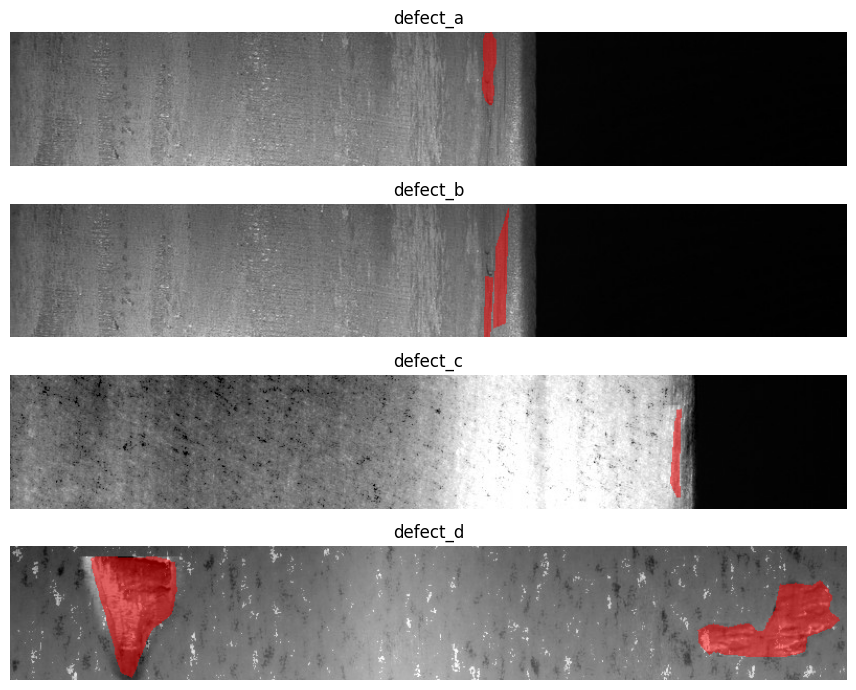

In [21]:
import matplotlib.pyplot as plt, cv2
from src.config import CLASSES
freq = labels[["has_a", "has_b", "has_c", "has_d"]].mean() * 100
print("images with each defect (%):", dict(zip(CLASSES, freq.round(1))))
print("clean images:", int((labels[["has_a","has_b","has_c","has_d"]].sum(axis=1) == 0).sum()), "of", len(labels))

fig, axes = plt.subplots(4, 1, figsize=(14, 7))
for ax, c in zip(axes, CLASSES):
    row = labels[labels["has_" + c[-1]] == 1].iloc[0]
    g = cv2.imread(f"{DATA_DIR}/train/{row.image_id}.jpg", 0)
    rgb = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB); m = rle_decode(row[c]).astype(bool)
    rgb[m] = (0.5 * rgb[m] + [127, 0, 0]).astype(np.uint8)
    ax.imshow(rgb); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Train the three models (second run, after fixing the loss - see the diagnosis below)
Each command is a single string passed to `run()`. About 2-2.5 min per epoch on a P100/T4; early stopping
(patience 7) may end runs sooner. Order matters: the **pretrained models first** - they decide the
leaderboard score - and the from-scratch U-Net last.

**Watch the first epochs:** every line now prints `dice a/b/c/d`. If `a` and `b` stay at 0.00 after ~5 epochs,
stop the run (Interrupt) rather than wasting hours. Everything is also logged to W&B.

In [22]:
run(f"python -m src.train --model fpn_effb3 --epochs 30 --patience 7 --balanced --batch_size 16 --lr 3e-4 --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/models")

$ python -m src.train --model fpn_effb3 --epochs 30 --patience 7 --balanced --batch_size 16 --lr 3e-4 --wandb_entity 23f1002246-dl-gen-ai --wandb_project 23f1002246-t32026 --out_dir /kaggle/working/models
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: setting up run 35kosmrl
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_091004-35kosmrl
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run fpn_effb3-bce_dice-bal
wandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20
wandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/35kosmrl
train 9114 | val 2279 | device cuda
ep 01 | train 0.3367 | val 0.2912 | score 

'Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.\nwandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.\nwandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin\nwandb: Using an existing wandb-core service via WANDB_SERVICE.\nwandb: setting up run 35kosmrl\nwandb: Tracking run with wandb version 0.28.1\nwandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_091004-35kosmrl\nwandb: Run `wandb offline` to turn off syncing.\nwandb: Syncing run fpn_effb3-bce_dice-bal\nwandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20\nwandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/35kosmrl\ntrain 9114 | val 2279 | device cuda\nep 01 | train 0.3367 | val 0.2912 | score 0.5930 | fg_dice 0.4743 | empty_acc 0.8697 | dice a/b/

In [23]:
run(f"python -m src.train --model unet_resnet34 --epochs 30 --patience 7 --balanced --batch_size 16 --lr 3e-4 --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/models")

$ python -m src.train --model unet_resnet34 --epochs 30 --patience 7 --balanced --batch_size 16 --lr 3e-4 --wandb_entity 23f1002246-dl-gen-ai --wandb_project 23f1002246-t32026 --out_dir /kaggle/working/models
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_102913-u5lkeift
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unet_resnet34-bce_dice-bal
wandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20
wandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/u5lkeift
train 9114 | val 2279 | device cuda
ep 01 | train 0.5220 | val 0.4314 | score 0.4775 | fg_dice 0.3274

'Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.\nwandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.\nwandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin\nwandb: Using an existing wandb-core service via WANDB_SERVICE.\nwandb: Tracking run with wandb version 0.28.1\nwandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_102913-u5lkeift\nwandb: Run `wandb offline` to turn off syncing.\nwandb: Syncing run unet_resnet34-bce_dice-bal\nwandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20\nwandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/u5lkeift\ntrain 9114 | val 2279 | device cuda\nep 01 | train 0.5220 | val 0.4314 | score 0.4775 | fg_dice 0.3274 | empty_acc 0.8279 | dice a/b/c/d 0.00/0.00/0.35/0.54 | 13

In [24]:
run(f"python -m src.train --model unet_scratch --epochs 30 --patience 7 --balanced --batch_size 16 --lr 1e-3 --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/models")

$ python -m src.train --model unet_scratch --epochs 30 --patience 7 --balanced --batch_size 16 --lr 1e-3 --wandb_entity 23f1002246-dl-gen-ai --wandb_project 23f1002246-t32026 --out_dir /kaggle/working/models
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_113505-ri1gfna5
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run unet_scratch-bce_dice-bal
wandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20
wandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/ri1gfna5
train 9114 | val 2279 | device cuda
ep 01 | train 0.5458 | val 0.4704 | score 0.3577 | fg_dice 0.1727 |

'wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.\nwandb: Currently logged in as: 23f1002246 (23f1002246-dl-gen-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin\nwandb: Using an existing wandb-core service via WANDB_SERVICE.\nwandb: Tracking run with wandb version 0.28.1\nwandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_113505-ri1gfna5\nwandb: Run `wandb offline` to turn off syncing.\nwandb: Syncing run unet_scratch-bce_dice-bal\nwandb: ⭐️ View project at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20\nwandb: 🚀 View run at https://wandb.ai/23f1002246-dl-gen-ai/23f1002246-t32026%20/runs/ri1gfna5\ntrain 9114 | val 2279 | device cuda\nep 01 | train 0.5458 | val 0.4704 | score 0.3577 | fg_dice 0.1727 | empty_acc 0.7893 | dice a/b/c/d 0.00/0.00/0.13/0.42 | 170s *\nep 02 | train 0.4653 | val 0.4538 | score 0.3961 | fg_dice 0.2576 | empty_acc 0.7193 | dice a/b/c/d 0.00/0.00/0.28/0.43 | 168s *\nep 0

In [25]:
import json
for name in MODEL_NAMES:
    p = f"/kaggle/working/models/{name}_summary.json"
    if os.path.exists(p):
        s = json.load(open(p)); print(f"{name:15s} best val score {s['best_score']:.4f}  ({s['params_M']:.1f}M params)")

unet_scratch    best val score 0.5881  (7.8M params)
unet_resnet34   best val score 0.6532  (24.4M params)
fpn_effb3       best val score 0.7151  (12.5M params)


### What went wrong in the first run, and how it was fixed (good viva material)
**Symptoms** (first run: per-image Dice loss, no balancing; public LB 0.576):
* `unet_scratch` and `unet_resnet34` reached their best epoch at **epoch 4 and epoch 2**, then collapsed:
  `fg_dice` fell to ~0 and `empty_acc` rose to ~1.0 - they learned to predict *nothing*.
* The error analysis showed **0 true positives for `defect_a` and `defect_b`** (216 + 62 positive validation
  images, all missed) - Dice 0 on two of four classes. Only `defect_c` (Dice 0.50) and `defect_d` (0.63) worked.
* Small defects were hardest: Dice 0.28 (c) and 0.09 (d) for the smallest quartile vs 0.60 / 0.73 for the largest.
* Threshold tuning could not help: for `a` and `b` the grid's lowest threshold (0.3) was still above every
  probability, and the ensemble (0.5949) was *worse* than FPN alone (0.6032) because the ResNet-34
  checkpoint came from epoch 2.

**Cause.** ~84% of (image, class) pairs are empty. In the per-image Dice loss an empty pair scores
Dice ~1 whenever the predicted probabilities sum to ~0, so "predict nothing everywhere" gives a low loss
for 84% of the pairs. Measured on real training masks, a network outputting a constant logit of -6, -10, -14
has per-image loss 0.52, 0.47, 0.17 (it keeps getting cheaper), while the new batch-level loss gives 0.53,
0.54, 0.56 (it gets worse). The observed final training losses (0.126 and 0.133) are close to that "predict
nothing" region; FPN's 0.066 shows it was still learning.

**Fixes.**
1. Dice per *class over the batch*, skipping classes absent from the batch -> no free reward for empties.
2. `--balanced`: images with `defect_a`/`defect_b` are drawn 3x as often (their share of each epoch rises
   from ~12% to ~30%), clean images halved.
3. Threshold grid now starts at 0.05, so a weakly-confident class can still be recovered.
4. Ensemble vs single model is chosen on validation instead of assumed (section 7).
5. `dice a/b/c/d` printed every epoch, so a dead class is visible after one epoch, not after the run.

**Honest limits.** I diagnosed the collapse from the logs and the loss values; I have not proven that
this is the only reason `a` and `b` failed - they may also be genuinely subtle (low-contrast) defects.
The second run tests it.

## 6. Experiments (Milestones 3-4) - run in a *separate* version to save GPU time
The fixed loss vs the original is already a finished comparison: the first run used `--loss bce_dice_img`
without `--balanced` (W&B runs `unet_scratch-bce_dice`, `unet_resnet34-bce_dice`, `fpn_effb3-bce_dice`).
More single-factor tests against the second-run `unet_resnet34` + `bce_dice` + `--balanced`:
* loss: `--loss bce` vs `--loss dice`
* imbalance: the same run **without** `--balanced`

Use a different `--out_dir` so the main checkpoints aren't overwritten.

In [26]:
# Uncomment ONE line at a time and run it in its own version.
# run(f"python -m src.train --model unet_resnet34 --epochs 30 --patience 7 --loss bce --balanced --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/exp_bce")
# run(f"python -m src.train --model unet_resnet34 --epochs 30 --patience 7 --loss dice --balanced --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/exp_dice")
# run(f"python -m src.train --model unet_resnet34 --epochs 30 --patience 7 --wandb_entity {WANDB_ENTITY} --wandb_project {WANDB_PROJECT} --out_dir /kaggle/working/exp_nobal")

## 7. Post-processing: choose the checkpoints, then tune thresholds (Milestone 5)
Three candidates are each tuned on the **validation** split (never on the leaderboard): all three models,
the two pretrained models, and FPN alone. The best tuned validation score wins. Averaging weak models can
*lower* the score (first run: ensemble 0.5949 < FPN alone 0.6032), so this is measured, not assumed.

In [27]:
import re
CK = "/kaggle/working/models"
CAND = {"all": ["unet_scratch", "unet_resnet34", "fpn_effb3"],
        "pretrained": ["unet_resnet34", "fpn_effb3"],
        "fpn": ["fpn_effb3"]}
results = {}
for key, names in CAND.items():
    ckpts = " ".join(f"{CK}/{n}.pt" for n in names)
    out = run(f"python -m src.tune_thresholds --tta --checkpoints {ckpts} --out {CK}/postprocess_{key}.json")
    results[key] = float(re.search(r"-> ([0-9.]+) \(tuned\)", out).group(1))
BEST = max(results, key=results.get)
CKPTS = " ".join(f"{CK}/{n}.pt" for n in CAND[BEST])
PP = f"{CK}/postprocess_{BEST}.json"
print("tuned validation scores:", results, "-> using:", BEST)

$ python -m src.tune_thresholds --tta --checkpoints /kaggle/working/models/unet_scratch.pt /kaggle/working/models/unet_resnet34.pt /kaggle/working/models/fpn_effb3.pt --out /kaggle/working/models/postprocess_all.json
loaded /kaggle/working/models/unet_scratch.pt (unet_scratch, epoch 29)
loaded /kaggle/working/models/unet_resnet34.pt (unet_resnet34, epoch 29)
loaded /kaggle/working/models/fpn_effb3.pt (fpn_effb3, epoch 29)
defect_a: threshold 0.4, min_area 50, fg dice 0.390, empty acc 0.973
defect_b: threshold 0.2, min_area 300, fg dice 0.449, empty acc 0.986
defect_c: threshold 0.3, min_area 150, fg dice 0.635, empty acc 0.868
defect_d: threshold 0.3, min_area 150, fg dice 0.704, empty acc 0.931
Validation score: 0.6855 (thr 0.5, no filtering) -> 0.7086 (tuned)
saved /kaggle/working/models/postprocess_all.json
$ python -m src.tune_thresholds --tta --checkpoints /kaggle/working/models/unet_resnet34.pt /kaggle/working/models/fpn_effb3.pt --out /kaggle/working/models/postprocess_pretraine

## 8. Error analysis
Which classes are missed, which produce false alarms, and does Dice drop for small defects? Compare with the first run: `defect_a` and `defect_b` had 0 true positives.

In [28]:
run(f"python -m src.analyze --tta --checkpoints {CKPTS} --postprocess {PP} --out_dir /kaggle/working/analysis")

$ python -m src.analyze --tta --checkpoints /kaggle/working/models/fpn_effb3.pt --postprocess /kaggle/working/models/postprocess_fpn.json --out_dir /kaggle/working/analysis
loaded /kaggle/working/models/fpn_effb3.pt (fpn_effb3, epoch 29)
kind       TP  FN   FP    TN  recall  precision  dice_when_present
cls                                                               
defect_a  148  68   82  1981   0.685      0.643              0.419
defect_b   40  22   13  2204   0.645      0.755              0.445
defect_c  754  67  148  1310   0.918      0.836              0.657
defect_d  310  31   42  1896   0.909      0.881              0.747

Mean Dice by ground-truth size quartile:
size      small  medium  large   huge
cls                                  
defect_a  0.381   0.506  0.490  0.000
defect_b  0.423   0.500  0.661    NaN
defect_c  0.475   0.624  0.675  0.795
defect_d  0.191   0.614  0.798  0.843
saved /kaggle/working/analysis/errors_defect_a.png
saved /kaggle/working/analysis/errors_d

'loaded /kaggle/working/models/fpn_effb3.pt (fpn_effb3, epoch 29)\nkind       TP  FN   FP    TN  recall  precision  dice_when_present\ncls                                                               \ndefect_a  148  68   82  1981   0.685      0.643              0.419\ndefect_b   40  22   13  2204   0.645      0.755              0.445\ndefect_c  754  67  148  1310   0.918      0.836              0.657\ndefect_d  310  31   42  1896   0.909      0.881              0.747\n\nMean Dice by ground-truth size quartile:\nsize      small  medium  large   huge\ncls                                  \ndefect_a  0.381   0.506  0.490  0.000\ndefect_b  0.423   0.500  0.661    NaN\ndefect_c  0.475   0.624  0.675  0.795\ndefect_d  0.191   0.614  0.798  0.843\nsaved /kaggle/working/analysis/errors_defect_a.png\nsaved /kaggle/working/analysis/errors_defect_b.png\nsaved /kaggle/working/analysis/errors_defect_c.png\nsaved /kaggle/working/analysis/errors_defect_d.png\n'

defect_a


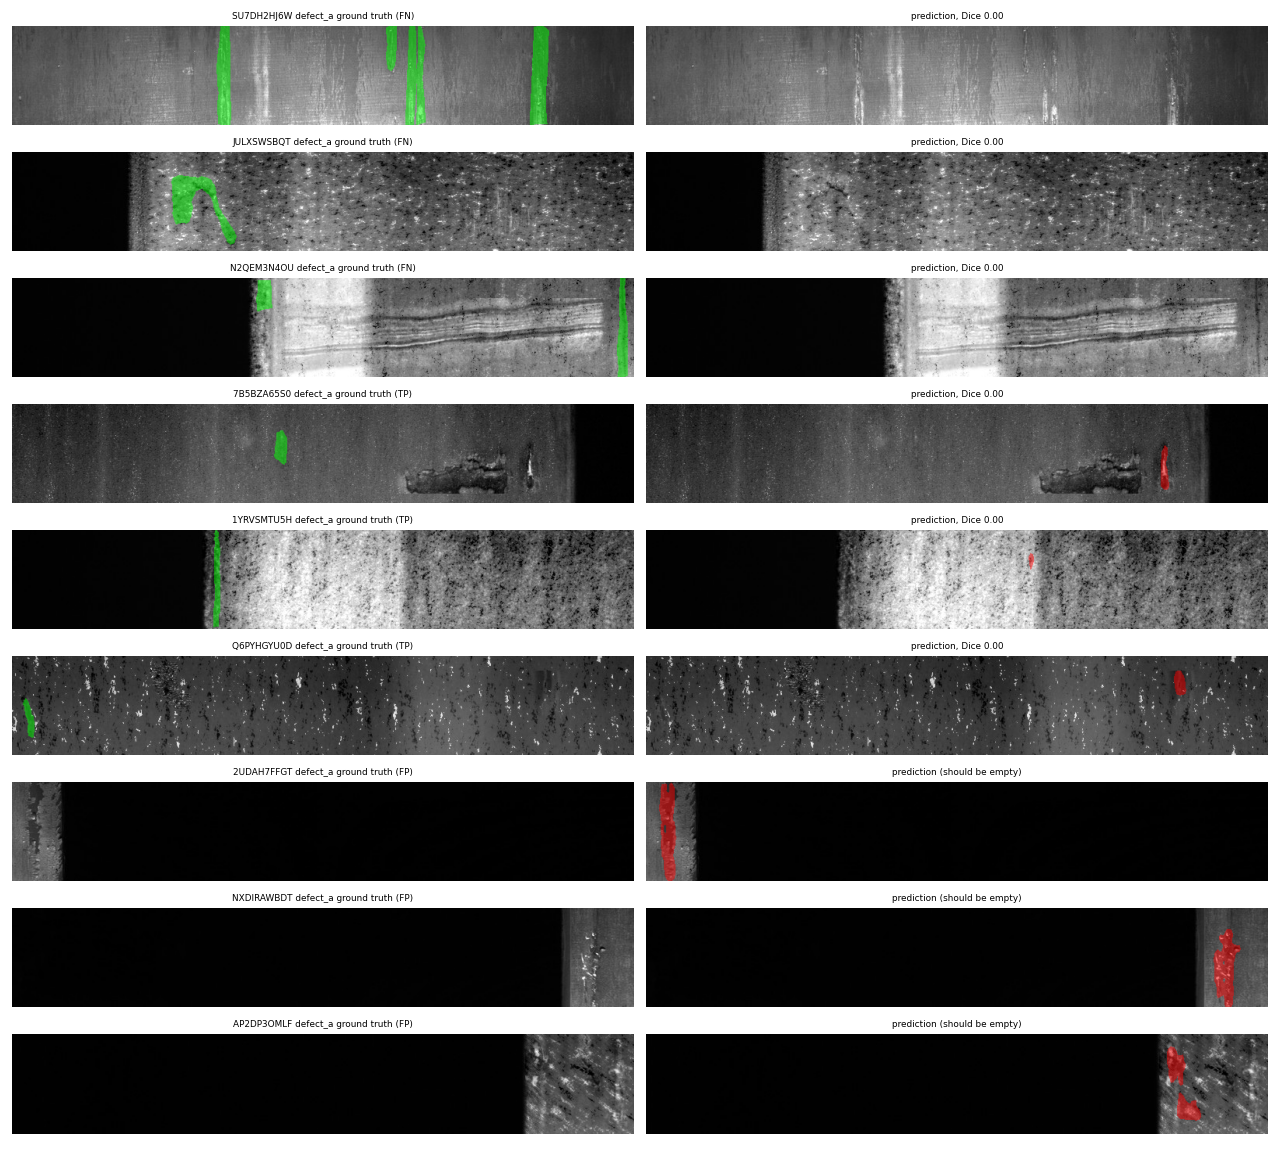

defect_b


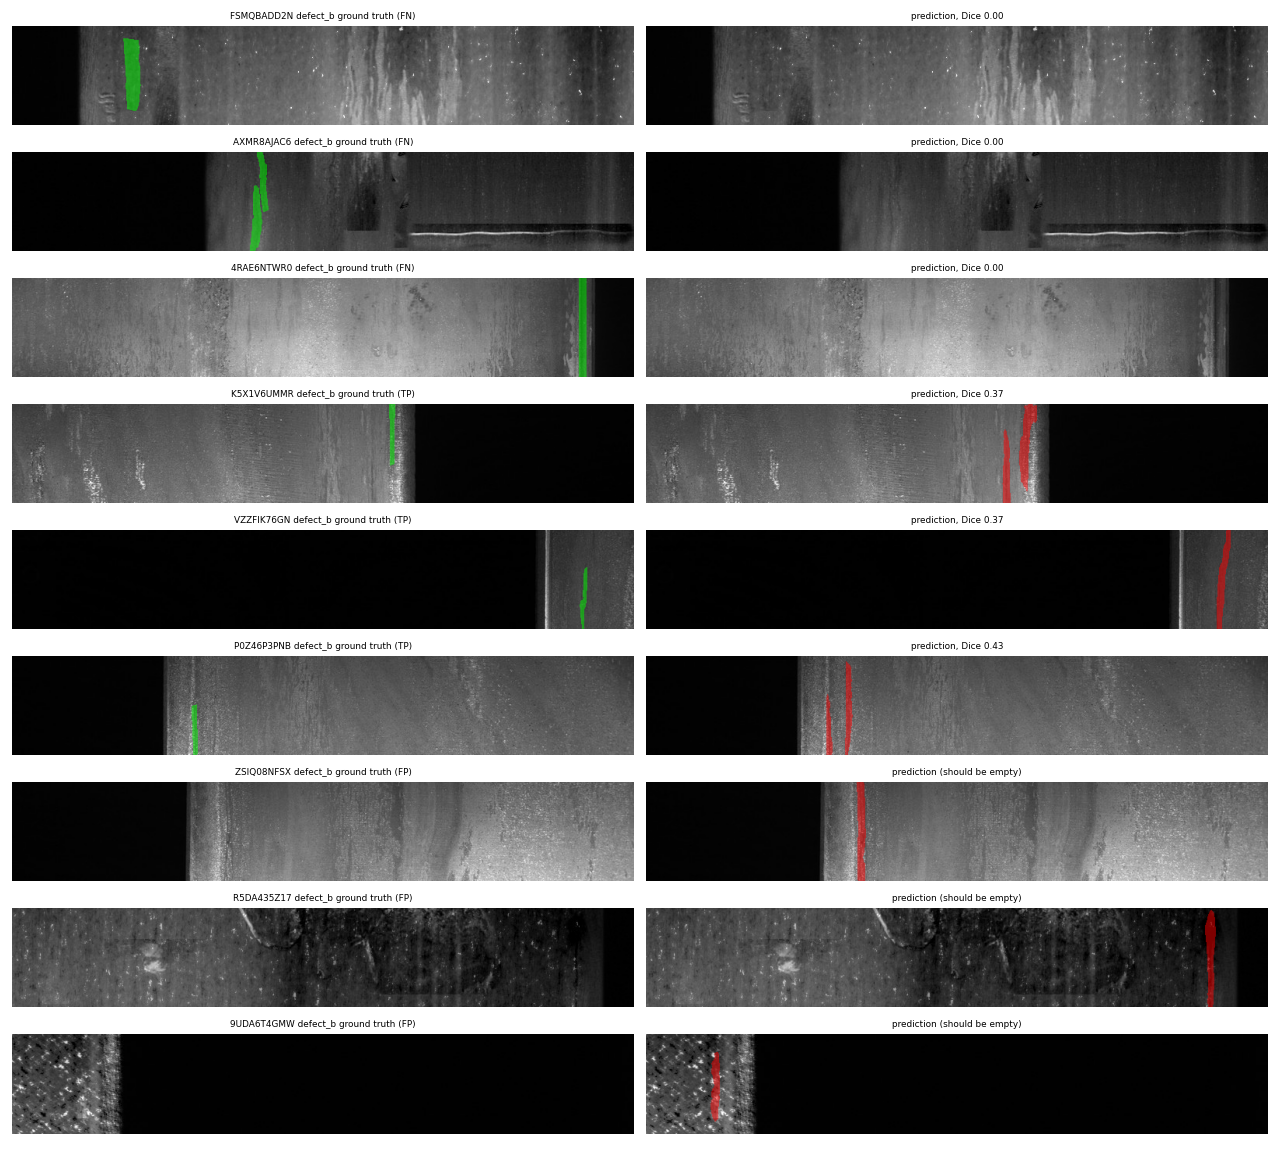

defect_c


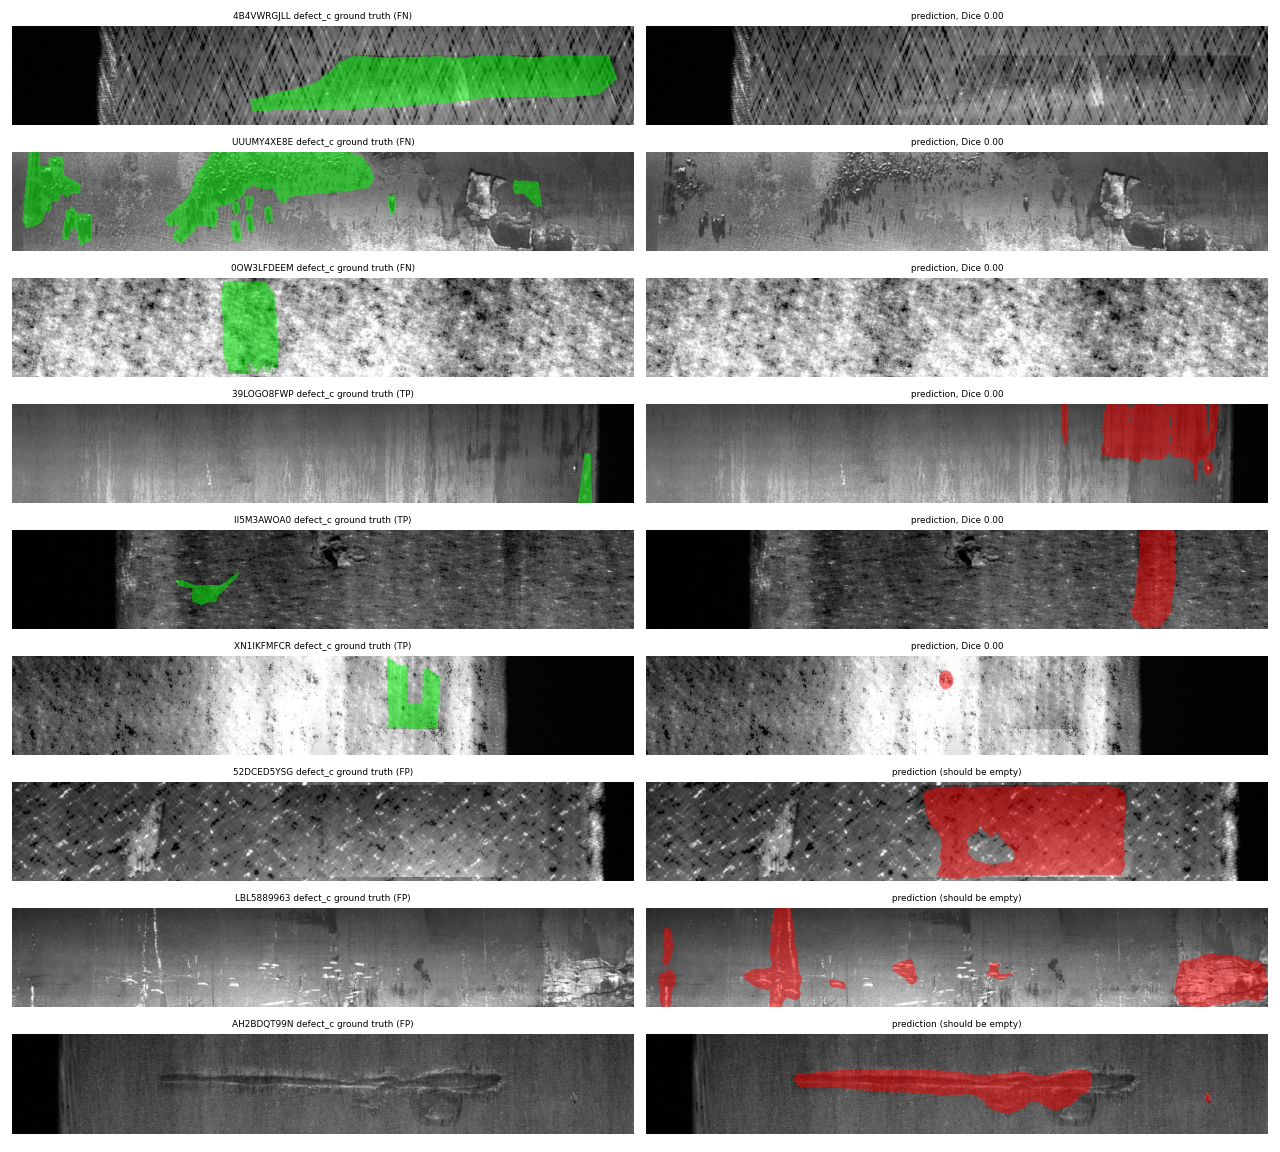

defect_d


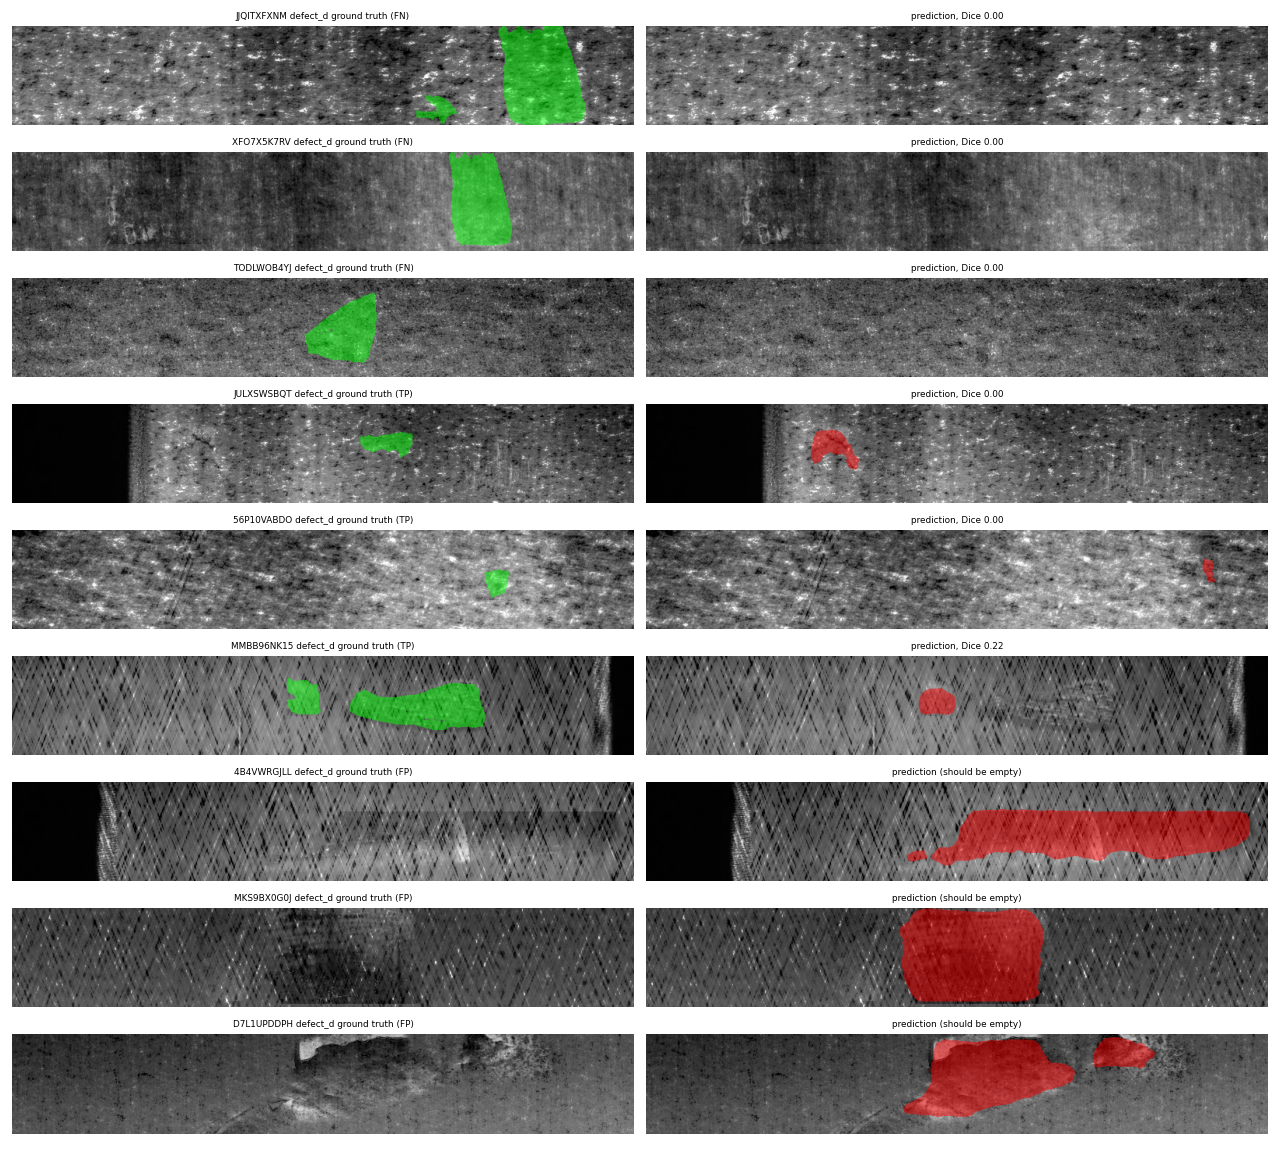

In [29]:
from IPython.display import Image, display
for c in CLASSES:
    p = f"/kaggle/working/analysis/errors_{c}.png"
    if os.path.exists(p):
        print(c); display(Image(p))

## 9. Final submission

In [30]:
run(f"python -m src.inference --tta --checkpoints {CKPTS} --postprocess {PP} --out /kaggle/working/submission.csv")

$ python -m src.inference --tta --checkpoints /kaggle/working/models/fpn_effb3.pt --postprocess /kaggle/working/models/postprocess_fpn.json --out /kaggle/working/submission.csv
thresholds [0.1, 0.1, 0.2, 0.2] min_areas [50, 300, 50, 150]
loaded /kaggle/working/models/fpn_effb3.pt (fpn_effb3, epoch 29)
wrote /kaggle/working/submission.csv (12000 rows). Fraction of non-empty predictions per class:
defect_type
defect_a    0.147
defect_b    0.043
defect_c    0.409
defect_d    0.308


'thresholds [0.1, 0.1, 0.2, 0.2] min_areas [50, 300, 50, 150]\nloaded /kaggle/working/models/fpn_effb3.pt (fpn_effb3, epoch 29)\nwrote /kaggle/working/submission.csv (12000 rows). Fraction of non-empty predictions per class:\ndefect_type\ndefect_a    0.147\ndefect_b    0.043\ndefect_c    0.409\ndefect_d    0.308\n'

In [31]:
sub = pd.read_csv("/kaggle/working/submission.csv", keep_default_na=False)
ref = pd.read_csv(f"{DATA_DIR}/sample_submission.csv", keep_default_na=False)
assert list(sub.columns) == list(ref.columns) and len(sub) == len(ref)
assert (sub[["ID", "image_id", "defect_type"]].values == ref[["ID", "image_id", "defect_type"]].values).all()
print("submission format OK:", sub.shape)
sub.head(8)

submission format OK: (12000, 4)


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


## 10. Results
**First run** (per-image Dice loss, no balancing):

| Model | Best epoch | Val score | Val fg Dice | Val empty acc | Public LB |
|---|---|---|---|---|---|
| Baseline (all empty) | - | 0.30 | 0 | 1.00 | (copied sample file: 0.273) |
| U-Net scratch (7.8 M) | 4 | 0.4420 | 0.27 | 0.85 | |
| U-Net ResNet-34 (24.4 M) | 2 | 0.5000 | 0.39 | 0.76 | |
| FPN EfficientNet-B3 (12.5 M) | 13 | 0.6032 | 0.44 | 0.98 | |
| Ensemble (ResNet-34 + FPN) + TTA + tuned | - | 0.5952 | - | - | **0.576** |

Per class (ensemble, validation): defect_a Dice 0.00, defect_b 0.00, defect_c 0.50 (recall 0.77, precision 0.86),
defect_d 0.63 (recall 0.84, precision 0.82).

**Second run** (batch-level Dice loss + `--balanced`, 30 epochs) - fill in:

| Model | Best epoch | Val score | Val fg Dice | Val empty acc | Dice a/b/c/d | Public LB |
|---|---|---|---|---|---|---|
| FPN EfficientNet-B3 | | | | | | |
| U-Net ResNet-34 | | | | | | |
| U-Net scratch | | | | | | |
| Best candidate + TTA + tuned post-processing | | | | | | |

**Observations** (write your own after looking at W&B and section 8):
* which model is best, and by how much does pretraining help over scratch?
* did `defect_a` / `defect_b` start to be detected after the loss fix and balancing, and at what cost to `defect_c` / `defect_d`?
* is the remaining problem misses (FN) or false alarms (FP), and does it concentrate in small defects?
* how much did threshold/min-area tuning add?

**Next steps:** longer training / k-fold ensemble, a classification head to decide "any defect of class c?"
before segmenting, larger encoders, pseudo-labelling the test set.